# Experiment 7 — Dimensionality Reduction Using PCA

**Aim:** Apply Principal Component Analysis to reduce numeric feature dimensionality and examine retained variance.

**Libraries:** pandas, NumPy, Matplotlib, and scikit-learn.

**Theory:** PCA forms orthogonal linear combinations ordered by explained variance. It is scale-sensitive and unsupervised; high explained variance does not guarantee better prediction.

**Dataset:** Wine dataset from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/109/wine), loaded with `sklearn.datasets.load_wine()` (13 features, 3 classes, 178 samples).

## Procedure / Implementation
The following cells load the data, apply the stated method, produce outputs, and record observations.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

for candidate in [Path("outputs"), Path("../outputs")]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

FIG_DIR = OUTPUT_DIR / "figures"
RES_DIR = OUTPUT_DIR / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the Wine dataset and standardise the features

Standardisation puts every feature on the same scale, which PCA requires (otherwise high-magnitude features would dominate the variance).

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="class")

print("Dataset shape:", X.shape)
print("Classes:", dict(zip(wine.target_names, np.bincount(y))))
X.head()

Dataset shape: (178, 13)
Classes: {np.str_('class_0'): np.int64(59), np.str_('class_1'): np.int64(71), np.str_('class_2'): np.int64(48)}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Mean after scaling (should be ~0):", np.round(X_scaled.mean(axis=0)[:5], 10))
print("Std  after scaling  (should be ~1):", np.round(X_scaled.std(axis=0)[:5], 6))

Mean after scaling (should be ~0): [ 0.  0. -0. -0. -0.]
Std  after scaling  (should be ~1): [1. 1. 1. 1. 1.]


## 2. Apply PCA and print the explained variance ratio

Each component's share of the total variance is printed. The first two components already carry a large part of the information.

In [4]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

evr = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(pca_full.explained_variance_ratio_))],
    "Explained variance ratio": pca_full.explained_variance_ratio_,
    "Cumulative": pca_full.explained_variance_ratio_.cumsum(),
})
print(evr.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Component  Explained variance ratio  Cumulative
      PC1                    0.3620      0.3620
      PC2                    0.1921      0.5541
      PC3                    0.1112      0.6653
      PC4                    0.0707      0.7360
      PC5                    0.0656      0.8016
      PC6                    0.0494      0.8510
      PC7                    0.0424      0.8934
      PC8                    0.0268      0.9202
      PC9                    0.0222      0.9424
     PC10                    0.0193      0.9617
     PC11                    0.0174      0.9791
     PC12                    0.0130      0.9920
     PC13                    0.0080      1.0000


## 3. Cumulative explained variance — how many components keep ~95%?

The number of components needed for 95% variance is marked on the plot.

Components needed for ~95% of the variance: 10


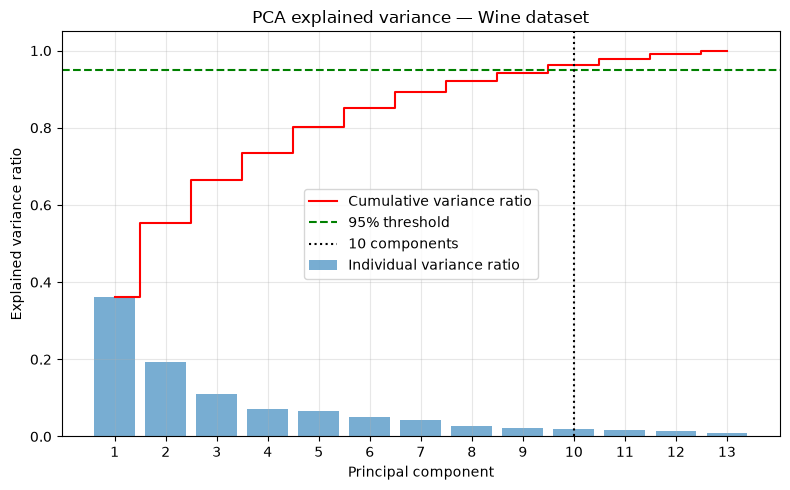

In [5]:
n95 = int(np.searchsorted(pca_full.explained_variance_ratio_.cumsum(), 0.95) + 1)
print(f"Components needed for ~95% of the variance: {n95}")

plt.figure(figsize=(8, 5))
components = np.arange(1, len(pca_full.explained_variance_ratio_) + 1)
plt.bar(components, pca_full.explained_variance_ratio_, alpha=0.6, label="Individual variance ratio")
plt.step(components, pca_full.explained_variance_ratio_.cumsum(), where="mid", color="red", label="Cumulative variance ratio")
plt.axhline(0.95, color="green", linestyle="--", label="95% threshold")
plt.axvline(n95, color="black", linestyle=":", label=f"{n95} components")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA explained variance — Wine dataset")
plt.xticks(components)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "exp07_cumulative_variance.png", dpi=150)
plt.show()

## 4. Plot the data on the first two principal components

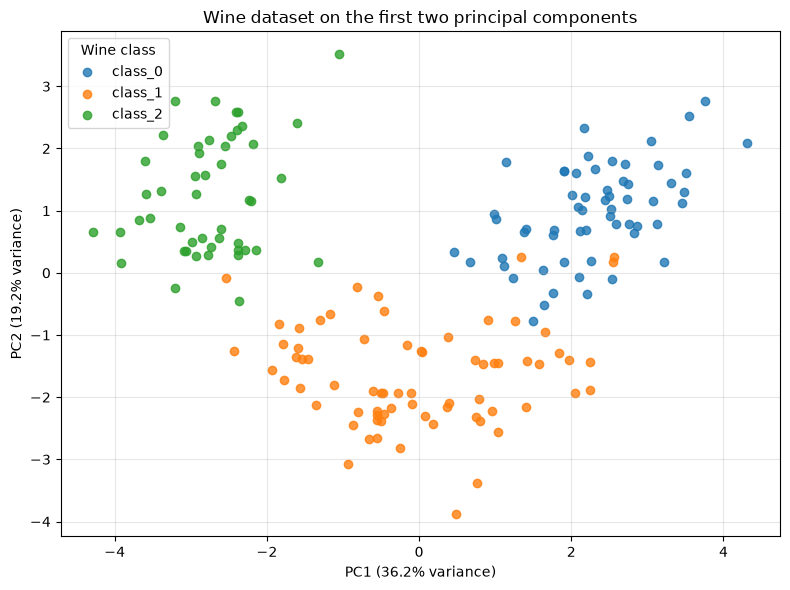

In [6]:
X_pca2 = pca_full.transform(X_scaled)[:, :2]

plt.figure(figsize=(8, 6))
for cls, name in enumerate(wine.target_names):
    mask = (y == cls).to_numpy()
    plt.scatter(X_pca2[mask, 0], X_pca2[mask, 1], label=name, alpha=0.8)

plt.xlabel(f"PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Wine dataset on the first two principal components")
plt.legend(title="Wine class")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "exp07_pca_scatter.png", dpi=150)
plt.show()

## 5. Classifier comparison: original features vs PCA features

To keep the evaluation honest, the scaler and the PCA transformation are re-fit **on the training split only**, then applied to the test split. Logistic Regression is used on (a) all 13 scaled features and (b) the first `n95` principal components.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Pipeline for the original (scaled) features
scaler_split = StandardScaler()
X_train_scaled = scaler_split.fit_transform(X_train)
X_test_scaled = scaler_split.transform(X_test)

clf_orig = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
clf_orig.fit(X_train_scaled, y_train)
acc_orig = accuracy_score(y_test, clf_orig.predict(X_test_scaled))

# Pipeline for the PCA features (PCA fit on train only)
pca_split = PCA(n_components=n95, random_state=RANDOM_STATE)
X_train_pca = pca_split.fit_transform(X_train_scaled)
X_test_pca = pca_split.transform(X_test_scaled)

clf_pca = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
clf_pca.fit(X_train_pca, y_train)
acc_pca = accuracy_score(y_test, clf_pca.predict(X_test_pca))

comparison = pd.DataFrame([
    {"Model": f"All {X.shape[1]} scaled features", "Test accuracy": acc_orig},
    {"Model": f"First {n95} principal components", "Test accuracy": acc_pca},
])
print(comparison.to_string(index=False))

comparison.to_csv(RES_DIR / "exp07_accuracy_comparison.csv", index=False)
print(f"\nSaved to {RES_DIR / 'exp07_accuracy_comparison.csv'}")

                        Model  Test accuracy
       All 13 scaled features       0.972222
First 10 principal components       0.972222

Saved to outputs\results\exp07_accuracy_comparison.csv


## Observation

Based on the run above:

1. PC1 captures **36.2%** of the variance and PC2 **19.2%** — together **55.4%** in two dimensions. The scatter plot shows the classes separating clearly: class_0 and class_2 sit at opposite ends of PC1 (mean PC1 = +2.3 vs −2.8), while class_1 separates mainly along PC2 (mean PC2 = −1.6).
2. **10 of the 13 components are needed to retain ~95% of the variance** (cumulative reaches 94.2% at PC9 and 96.2% at PC10), so the original features are moderately correlated and about 3 can be discarded with little loss.
3. Logistic Regression test accuracy was **97.2% on all 13 scaled features and 97.2% on the first 10 PCs** — dropping the last 3 components (4.2% of variance) cost no accuracy at all.
4. Overall, PCA compressed the dataset by ~23% with zero performance loss here; on larger, noisier datasets the same compression typically also speeds up training.

## Result

The executed cells above provide the measured result for this experiment. The conclusion should be interpreted using the dataset and evaluation limits stated here.